# Bài kiểm tra 3 – Tối ưu hóa, cải tiến và so sánh mô hình
**Đề tài:** So sánh các thuật toán học máy truyền thống trong dự đoán tương tác thuốc dựa trên cấu trúc hóa học
**Cần chạy trước:** `02_HuanLuyen_DanhGia.ipynb` (dùng lại kết quả kiểm định chéo của mô hình ban đầu trong `results/bkt2_cv_folds.csv`).

| Mục | Nội dung | Tiêu chí KT3 |
|---|---|---|
| 1 | Bằng chứng về hạn chế của mô hình ban đầu: chênh lệch train – validation, đường cong học tập, phụ thuộc thứ tự cặp, thuốc mới | 1 |
| 2 | Bảng hạn chế – giải pháp | 2 |
| 3 | Cải tiến đặc trưng: dự đoán hai chiều (trung bình hai thứ tự); biểu diễn cặp đối xứng; Morgan dạng đếm + đặc trưng hóa lý | 3 |
| 4 | Tối ưu siêu tham số bằng Random Search trên kiểm định chéo (không dùng tập kiểm tra); đường cong kiểm định | 5 |
| 5 | Thuật toán / cấu hình khác: Extra Trees, Soft Voting (RF + XGBoost) | 4 |
| 6 | So sánh trước – sau, đóng góp từng thay đổi (ablation) | 6, 8 |
| 7 | Mô hình cuối trên tập kiểm tra giữ lại và trên thuốc mới (S1, S2) | 7, 8 |
| 8 | Thí nghiệm kiểm tra thiên lệch theo bậc: lấy mẫu âm cân bằng theo bậc | 1, 7 |
| 9 | Lựa chọn mô hình cuối | 9 |

Chạy: *Run All* trong thư mục `notebooks/`. Chạy lần đầu mất khoảng 3 giờ trên CPU 2 nhân (lâu nhất là tìm siêu tham số);
các bước tốn thời gian được lưu vào `results/cache/` nên các lần chạy sau chỉ mất khoảng 10 phút (xóa `results/cache/` để tính lại từ đầu). `SEED = 42`.

In [1]:
import os, sys, json, time, warnings, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, ParameterSampler, train_test_split, learning_curve, cross_val_score
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score, accuracy_score
from xgboost import XGBClassifier
sys.path.insert(0, "../src")
from ddi_features import load_data, fingerprints, build_pairs, to_float32, cached
warnings.filterwarnings("ignore")

SEED = 42
PROC, RES, FIG = "../data/processed", "../results", "../LaTeX/images"
CACHE = f"{RES}/cache"                      # kết quả trung gian đã tính (xóa để chạy lại từ đầu)
os.makedirs(RES, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
BLUE, NAVY, LB, OR, GR, RED = "#1B75BB", "#0E3A66", "#9CC3E6", "#F2A541", "#B0B7C3", "#C0392B"
SUM = {}
QUICK = os.environ.get("DDI_QUICK") == "1"  # chạy thử nhanh trên tập con (mặc định: tắt)
def savefig(name):
    plt.savefig(f"{FIG}/{name}", bbox_inches="tight"); plt.show()
def C(key):
    return f"{CACHE}/bkt3_{key}{'_quick' if QUICK else ''}.joblib"
def vn(x, d=3): return f"{x:.{d}f}".replace(".", ",")
BKT2 = json.load(open(f"{RES}/bkt2_summary.json"))
cv_old = pd.read_csv(f"{RES}/bkt2_cv_folds.csv")

## 0. Dữ liệu và các cách biểu diễn cặp thuốc
- `concat`: [FP(A) ‖ FP(B)] – cách ban đầu, A là thuốc có mã nhỏ hơn.
- `concat` + **dự đoán hai chiều**: mô hình học như cũ, khi dự đoán lấy trung bình xác suất của (A, B) và (B, A) → đầu ra đối xứng, không mất thông tin.
  (Tăng cường dữ liệu bằng cách nhân đôi tập huấn luyện với thứ tự đảo cần hơn 6 GB RAM với Random Forest nên không thực hiện được trên máy của nhóm.)
- `sum`: FP(A) + FP(B) – đối xứng, 1.191 chiều.
- `sum_plus`: Morgan dạng đếm + MACCS (tổng hai thuốc) + 9 đặc trưng hóa lý (tổng và |hiệu|).

In [2]:
drugs, pairs = load_data(PROC); fps = fingerprints(drugs)
train_df = pairs[pairs.split == "train"].reset_index(drop=True); test_df = pairs[pairs.split == "test"].reset_index(drop=True)
if QUICK: train_df, test_df = train_df.iloc[:4000].reset_index(drop=True), test_df.iloc[:2000].reset_index(drop=True)
y_train, y_test = train_df.label.values, test_df.label.values
def swap(df): return df.rename(columns={"drug1": "drug2", "drug2": "drug1"})
class Reps(dict):
    """Tạo ma trận đặc trưng theo yêu cầu (chỉ khi cần) để tiết kiệm bộ nhớ."""
    def __init__(self, df, swapped=False): super().__init__(); self.df = swap(df) if swapped else df
    def __missing__(self, k): self[k] = build_pairs(self.df, drugs, fps, k); return self[k]
Xtr, Xte, Xtr_sw, Xte_sw = Reps(train_df), Reps(test_df), Reps(train_df, True), Reps(test_df, True)
print("concat:", Xtr["concat"].shape, "| sum:", (len(train_df), 1191), "| sum_plus:", (len(train_df), 1209))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # cùng cách chia với Bài kiểm tra 2
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
METRICS = ["roc_auc", "f1", "recall", "precision", "accuracy"]

concat: (80000, 2382) | sum: (80000, 1191) | sum_plus: (80000, 1209)


In [3]:
f32 = ("float32", FunctionTransformer(to_float32))
def lr(C=1.0):
    return Pipeline([f32, ("loc_hang_so", VarianceThreshold(0.0)), ("chuan_hoa", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=3000, random_state=SEED))])
def rf(**kw):
    p = dict(n_estimators=300, max_features="sqrt", n_jobs=2, random_state=SEED); p.update(kw)
    return Pipeline([("loc_hang_so", VarianceThreshold(0.0)), ("clf", RandomForestClassifier(**p))])
def et(**kw):
    p = dict(n_estimators=300, max_features="sqrt", n_jobs=2, random_state=SEED); p.update(kw)
    return Pipeline([("loc_hang_so", VarianceThreshold(0.0)), ("clf", ExtraTreesClassifier(**p))])
def xgb(**kw):
    p = dict(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5, tree_method="hist",
             n_jobs=2, eval_metric="logloss", random_state=SEED); p.update(kw)
    return Pipeline([("loc_hang_so", VarianceThreshold(0.0)), ("clf", XGBClassifier(**p))])

def scores(y, p):
    yhat = (p >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "f1": f1_score(y, yhat), "recall": recall_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "accuracy": accuracy_score(y, yhat)}

def fit_predict(model, X_fit, y_fit, X_eval, aug=False, Xs_fit=None, Xs_eval=None):
    """Huấn luyện rồi dự đoán. aug=True (dự đoán hai chiều): xác suất = trung bình của (A, B) và (B, A)."""
    m = clone(model).fit(X_fit, y_fit)
    p = m.predict_proba(X_eval)[:, 1]
    if aug: p = (p + m.predict_proba(Xs_eval)[:, 1]) / 2
    return m, p

OOF, ROWS = {}, []
def run_cv(name, model, rep, aug=False):
    """Kiểm định chéo 5-fold (cùng `cv` với Bài kiểm tra 2); lưu xác suất ngoài fold để kết hợp mô hình mà không phải huấn luyện lại."""
    X, Xs, y = Xtr[rep], (Xtr_sw[rep] if aug else None), y_train
    t_all = time.time()
    def _run():
        oof, rows = np.zeros(len(y)), []
        for k, (tr, va) in enumerate(cv.split(X, y)):
            t0 = time.time()
            m, p = fit_predict(model, X[tr], y[tr], X[va], aug, Xs[tr] if aug else None, Xs[va] if aug else None)
            ft = time.time() - t0; oof[va] = p
            p_tr = (m.predict_proba(X[tr])[:, 1] + m.predict_proba(Xs[tr])[:, 1]) / 2 if aug else m.predict_proba(X[tr])[:, 1]
            rows.append({"Cấu hình": name, "Fold": k + 1, **scores(y[va], p), "train_roc_auc": roc_auc_score(y[tr], p_tr), "fit_time": ft})
            del m; gc.collect()                 # giải phóng bộ nhớ (mô hình rừng cây rất lớn)
        return {"oof": oof, "rows": rows}
    out = cached(C("cv_" + "".join(ch if ch.isalnum() else "_" for ch in name)), _run)
    ROWS.extend(out["rows"]); OOF[name] = out["oof"]
    r = pd.DataFrame(out["rows"])
    print(f"{name:44s} ROC-AUC = {r.roc_auc.mean():.4f} ± {r.roc_auc.std(ddof=0):.4f}  F1 = {r.f1.mean():.4f}  ({time.time() - t_all:.0f} s)")
    return r

def add_old(name, old_name):
    """Dùng lại kết quả kiểm định chéo của Bài kiểm tra 2 (cùng dữ liệu, cùng cách chia)."""
    for _, r in cv_old[cv_old["Mô hình"] == old_name].iterrows():
        ROWS.append({"Cấu hình": name, "Fold": int(r.Fold), **{m: r[m] for m in METRICS}, "train_roc_auc": r.train_roc_auc, "fit_time": r.fit_time})

## 1. Bằng chứng về hạn chế của mô hình ban đầu
### 1a. Chênh lệch huấn luyện – kiểm định (từ Bài kiểm tra 2) và đường cong học tập

In [4]:
gap = pd.DataFrame({n: {"ROC-AUC train": BKT2["cv"][n]["train_roc_auc"], "ROC-AUC validation": BKT2["cv"][n]["roc_auc"][0]}
                    for n in ["Logistic Regression", "Random Forest", "XGBoost"]}).T
gap["Chênh lệch"] = gap.iloc[:, 0] - gap.iloc[:, 1]; display(gap.round(4)); SUM["gap_bkt2"] = gap.round(5).to_dict(orient="index")
sizes = [0.15, 0.35, 0.65, 1.0]; LC = {}
for name, model in [("XGBoost", xgb()), ("Random Forest", rf())]:
    n_abs, tr_s, va_s = cached(C(f"lc_{name.replace(' ', '_')}"), lambda: learning_curve(model, Xtr["concat"], y_train, train_sizes=sizes, cv=cv3,
                                                                                          scoring="roc_auc", shuffle=True, random_state=SEED))
    LC[name] = {"n": n_abs.tolist(), "train": tr_s.mean(1).tolist(), "val": va_s.mean(1).tolist(), "val_sd": va_s.std(1).tolist()}
    print(name, [f"{n}: {a:.3f}/{b:.3f}" for n, a, b in zip(n_abs, tr_s.mean(1), va_s.mean(1))])
SUM["learning_curve"] = LC

,ROC-AUC train,ROC-AUC validation,Chênh lệch
Logistic Regression,0.8365,0.8067,0.0298
Random Forest,1.0000,0.8582,0.1418
XGBoost,0.9277,0.8470,0.0806


XGBoost ['7999: 0.997/0.756', '18666: 0.980/0.804', '34666: 0.954/0.829', '53333: 0.935/0.843']
Random Forest ['7999: 1.000/0.757', '18666: 1.000/0.801', '34666: 1.000/0.833', '53333: 1.000/0.852']


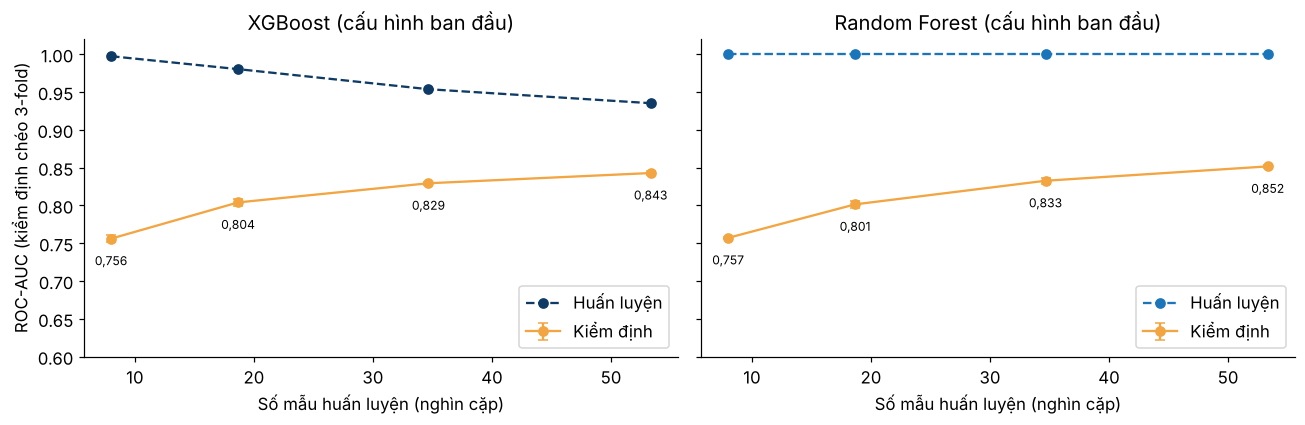

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (name, c) in zip(ax, [("XGBoost", NAVY), ("Random Forest", BLUE)]):
    d = LC[name]; n = np.array(d["n"]) / 1000
    a.plot(n, d["train"], "o--", color=c, label="Huấn luyện"); a.errorbar(n, d["val"], yerr=d["val_sd"], fmt="o-", color=OR, capsize=3, label="Kiểm định")
    for x, v in zip(n, d["val"]): a.text(x, v - 0.035, vn(v), ha="center", fontsize=8)
    a.set_xlabel("Số mẫu huấn luyện (nghìn cặp)"); a.set_title(f"{name} (cấu hình ban đầu)"); a.legend(loc="lower right")
ax[0].set_ylabel("ROC-AUC (kiểm định chéo 3-fold)"); ax[0].set_ylim(0.6, 1.02)
plt.tight_layout(); savefig("fig13_duong_cong_hoc.png")

### 1b. Mô hình ban đầu phụ thuộc thứ tự hai thuốc trong cặp
Cặp (A, B) và (B, A) là cùng một cặp thuốc, nhưng cách ghép nối [FP(A) ‖ FP(B)] cho hai vectơ khác nhau. Ta đổi chỗ hai thuốc ở
tập kiểm tra và xem xác suất dự đoán thay đổi thế nào (Random Forest và XGBoost ban đầu, huấn luyện trên toàn bộ tập huấn luyện).

,mean_abs_diff,p90_abs_diff,flip_rate,auc_ab,auc_ba,auc_avg
Random Forest,0.1196,0.2500,0.2268,0.8646,0.7961,0.8606
XGBoost,0.1335,0.2864,0.2177,0.8525,0.7766,0.8426


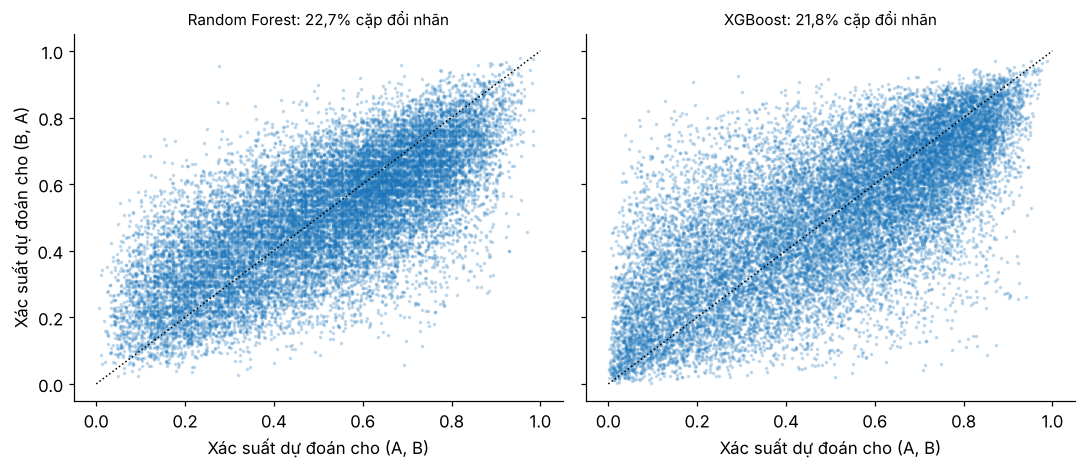

In [6]:
def _order(make):
    m, p = fit_predict(make(), Xtr["concat"], y_train, Xte["concat"]); p_sw = m.predict_proba(Xte_sw["concat"])[:, 1]
    del m; gc.collect(); return p, p_sw     # giải phóng bộ nhớ trước khi huấn luyện mô hình tiếp theo
p_rf0, p_rf0_sw = cached(C("order_rf0"), lambda: _order(rf))
p_xgb0, p_xgb0_sw = cached(C("order_xgb0"), lambda: _order(xgb))
ORDER = {}
for n, a, b in [("Random Forest", p_rf0, p_rf0_sw), ("XGBoost", p_xgb0, p_xgb0_sw)]:
    ORDER[n] = {"mean_abs_diff": float(np.abs(a - b).mean()), "p90_abs_diff": float(np.quantile(np.abs(a - b), 0.9)),
                "flip_rate": float(((a >= 0.5) != (b >= 0.5)).mean()), "auc_ab": roc_auc_score(y_test, a), "auc_ba": roc_auc_score(y_test, b),
                "auc_avg": roc_auc_score(y_test, (a + b) / 2)}
display(pd.DataFrame(ORDER).T.round(4)); SUM["order"] = ORDER
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for a, (n, x, y_) in zip(ax, [("Random Forest", p_rf0, p_rf0_sw), ("XGBoost", p_xgb0, p_xgb0_sw)]):
    a.scatter(x, y_, s=2, alpha=0.2, color=BLUE); a.plot([0, 1], [0, 1], "k:", lw=1)
    a.set_xlabel("Xác suất dự đoán cho (A, B)"); a.set_title(f"{n}: {ORDER[n]['flip_rate']:.1%} cặp đổi nhãn".replace(".", ","), fontsize=10)
ax[0].set_ylabel("Xác suất dự đoán cho (B, A)"); plt.tight_layout(); savefig("fig14_thu_tu_cap.png")

### 1c. Hiệu năng giảm mạnh với thuốc mới (chia theo nhóm thuốc)

In [7]:
known = pairs[pairs.cold_group == "train_known"].reset_index(drop=True)
S = {g: pairs[pairs.cold_group == g].reset_index(drop=True) for g in ["S1_one_new", "S2_two_new"]}
if QUICK: known = known.iloc[:4000]; S = {g: d.iloc[:1500] for g, d in S.items()}
def cold_eval(key, make, rep, aug=False):
    def _f():
        Xk, yk = build_pairs(known, drugs, fps, rep), known.label.values
        m, _ = fit_predict(make(), Xk, yk, Xk[:2])
        out = {}
        for g, d in S.items():
            p = m.predict_proba(build_pairs(d, drugs, fps, rep))[:, 1]
            if aug: p = (p + m.predict_proba(build_pairs(swap(d), drugs, fps, rep))[:, 1]) / 2
            out[g] = roc_auc_score(d.label.values, p)
        del m; gc.collect(); return out
    return cached(C(f"cold_{key}"), _f)
COLD = {"XGBoost ban đầu": cold_eval("xgb0", xgb, "concat"), "Random Forest ban đầu": cold_eval("rf0", rf, "concat")}
print(COLD)

{'XGBoost ban đầu': {'S1_one_new': 0.7736197940045021, 'S2_two_new': 0.6801111434654991}, 'Random Forest ban đầu': {'S1_one_new': 0.799016658124904, 'S2_two_new': 0.7203725751103018}}


## 2. Hạn chế và giải pháp đề xuất
| Hạn chế (bằng chứng) | Giải pháp | Cơ sở |
|---|---|---|
| H1. Dự đoán phụ thuộc thứ tự A/B (mục 1b), độ quan trọng lệch về thuốc B (BKT2) | **Dự đoán hai chiều** (trung bình hai thứ tự); biểu diễn **đối xứng** FP(A) + FP(B) | Cặp không thứ tự cần hàm dự đoán đối xứng; trung bình hai “góc nhìn” còn giảm phương sai |
| H2. Vân tay nhị phân mất thông tin số lần xuất hiện và tính chất hóa lý | Morgan **dạng đếm** + 9 đặc trưng hóa lý (tổng, \|hiệu\|) | Tương tác dược động học phụ thuộc độ ưa béo, kích thước, số nhóm chức |
| H3. Quá khớp (RF train = 1,0; XGB chênh 0,08), siêu tham số mặc định (mục 1a) | **Random Search** trên kiểm định chéo (độ sâu, số cây, điều chuẩn, số đặc trưng mỗi nút) | Kiểm soát độ phức tạp, đánh đổi độ chệch – phương sai |
| H4. Mỗi mô hình đơn lẻ có phương sai riêng | **Extra Trees**, **Soft Voting** RF + XGBoost | Ngẫu nhiên hóa, kết hợp mô hình có lỗi khác nhau làm giảm phương sai |
| H5. Lỗi tập trung theo bậc thuốc, giảm mạnh với thuốc mới (BKT2, mục 1c) | Thí nghiệm **lấy mẫu âm cân bằng theo bậc** để đo phần hiệu năng đến từ “độ phổ biến” | Loại lối tắt (shortcut) do cách lấy mẫu âm |

## 3. Cải tiến dữ liệu và đặc trưng (siêu tham số mặc định, cùng 5 fold)

In [8]:
add_old("LR · ghép nối (ban đầu)", "Logistic Regression"); add_old("RF · ghép nối (ban đầu)", "Random Forest"); add_old("XGB · ghép nối (ban đầu)", "XGBoost")
REP_CFG = {"ghép nối + dự đoán hai chiều": ("concat", True), "đối xứng": ("sum", False), "đối xứng + đếm + hóa lý": ("sum_plus", False)}
for lab, (rep, aug) in REP_CFG.items():
    run_cv(f"LR · {lab}", lr(), rep, aug); run_cv(f"RF · {lab}", rf(), rep, aug); run_cv(f"XGB · {lab}", xgb(), rep, aug)

LR · ghép nối + dự đoán hai chiều            ROC-AUC = 0.7838 ± 0.0031  F1 = 0.7154  (0 s)
RF · ghép nối + dự đoán hai chiều            ROC-AUC = 0.8543 ± 0.0025  F1 = 0.7780  (0 s)
XGB · ghép nối + dự đoán hai chiều           ROC-AUC = 0.8384 ± 0.0032  F1 = 0.7645  (0 s)


LR · đối xứng                                ROC-AUC = 0.7930 ± 0.0027  F1 = 0.7275  (0 s)
RF · đối xứng                                ROC-AUC = 0.8507 ± 0.0029  F1 = 0.7764  (0 s)
XGB · đối xứng                               ROC-AUC = 0.8534 ± 0.0027  F1 = 0.7758  (0 s)


LR · đối xứng + đếm + hóa lý                 ROC-AUC = 0.8033 ± 0.0023  F1 = 0.7347  (0 s)
RF · đối xứng + đếm + hóa lý                 ROC-AUC = 0.8455 ± 0.0033  F1 = 0.7715  (0 s)
XGB · đối xứng + đếm + hóa lý                ROC-AUC = 0.8537 ± 0.0016  F1 = 0.7789  (0 s)


In [9]:
res = pd.DataFrame(ROWS); agg = res.groupby("Cấu hình", sort=False)
tab = pd.DataFrame({"ROC-AUC": agg.roc_auc.mean(), "± ĐLC": agg.roc_auc.std(ddof=0), "F1": agg.f1.mean(), "Recall": agg.recall.mean()})
display(tab.round(4))
ALL_CFG = {"ghép nối": ("concat", False), **REP_CFG}
BEST = {}
for fam in ["RF", "XGB"]:
    lab = max(ALL_CFG, key=lambda l: tab.loc[f"{fam} · {l}" if l != "ghép nối" else f"{fam} · ghép nối (ban đầu)", "ROC-AUC"])
    BEST[fam] = {"label": lab, "rep": ALL_CFG[lab][0], "aug": ALL_CFG[lab][1]}
print("Biểu diễn tốt nhất:", BEST); SUM["best_rep"] = BEST

,ROC-AUC,± ĐLC,F1,Recall
Cấu hình,,,,
LR · ghép nối (ban đầu),0.8067,0.0026,0.7386,0.7562
RF · ghép nối (ban đầu),0.8582,0.0022,0.7834,0.8091
XGB · ghép nối (ban đầu),0.8470,0.0017,0.7726,0.7993
LR · ghép nối + dự đoán hai chiều,0.7838,0.0031,0.7154,0.7348
RF · ghép nối + dự đoán hai chiều,0.8543,0.0025,0.7780,0.8012
XGB · ghép nối + dự đoán hai chiều,0.8384,0.0032,0.7645,0.7871
LR · đối xứng,0.7930,0.0027,0.7275,0.7445
RF · đối xứng,0.8507,0.0029,0.7764,0.8018
XGB · đối xứng,0.8534,0.0027,0.7758,0.7955


Biểu diễn tốt nhất: {'RF': {'label': 'ghép nối', 'rep': 'concat', 'aug': False}, 'XGB': {'label': 'đối xứng + đếm + hóa lý', 'rep': 'sum_plus', 'aug': False}}


## 4. Tối ưu siêu tham số (Random Search, kiểm định chéo 3-fold)
Mỗi mô hình được tối ưu trên biểu diễn tốt nhất của nó ở mục 3. Để vừa thời gian (CPU 2 nhân), việc tìm kiếm chạy trên
**30.000 mẫu lấy phân tầng từ tập huấn luyện**. Cấu hình tốt nhất sau đó được đánh giá lại bằng kiểm định chéo
5-fold trên toàn bộ 80.000 mẫu (mục 5). **Tập kiểm tra không được dùng.**

In [10]:
sub, _ = train_test_split(np.arange(len(y_train)), train_size=1500 if QUICK else 30000, stratify=y_train, random_state=SEED)
def cv3_score(make, params, rep, aug):
    X, y = Xtr[rep][sub], y_train[sub]; Xs = Xtr_sw["concat"][sub] if aug else None; sc = []
    for tr, va in cv3.split(X, y):
        _, p = fit_predict(make(**params), X[tr], y[tr], X[va], aug, Xs[tr] if aug else None, Xs[va] if aug else None)
        sc.append(roc_auc_score(y[va], p))
    return float(np.mean(sc)), float(np.std(sc))
space = {"XGB": {"n_estimators": randint(300, 901), "max_depth": [4, 6, 8, 10], "learning_rate": loguniform(0.02, 0.2),
                 "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.3, 0.6), "min_child_weight": [1, 3, 5], "reg_lambda": loguniform(0.5, 10)},
         "RF": {"n_estimators": [300, 500], "max_features": ["sqrt", 0.05, 0.1], "min_samples_leaf": [1, 2, 4], "max_depth": [None, 40]}}
make = {"XGB": xgb, "RF": rf}; n_iter = {"XGB": 2 if QUICK else 10, "RF": 2 if QUICK else 6}
SEARCH = {}
for fam in ["XGB", "RF"]:
    rep, aug = BEST[fam]["rep"], BEST[fam]["aug"]
    def _search():
        out = []
        for prm in ParameterSampler(space[fam], n_iter=n_iter[fam], random_state=SEED):
            prm = {k: (v.item() if hasattr(v, "item") else v) for k, v in prm.items()}
            t0 = time.time(); mu, sd = cv3_score(make[fam], prm, rep, aug); out.append({"params": prm, "mean": mu, "std": sd, "time": time.time() - t0})
        return out
    trials = cached(C(f"search_{fam}_{rep}{'_aug' if aug else ''}"), _search)
    default = cached(C(f"default_{fam}_{rep}{'_aug' if aug else ''}"), lambda: cv3_score(make[fam], {}, rep, aug))
    tr_df = pd.DataFrame(trials).sort_values("mean", ascending=False)
    SEARCH[fam] = {"best_params": tr_df.iloc[0]["params"], "best_score": float(tr_df.iloc[0]["mean"]), "best_std": float(tr_df.iloc[0]["std"]),
                   "default_score": default[0], "n_iter": n_iter[fam], "time_s": float(tr_df["time"].sum()), "rep": rep, "aug": aug,
                   "trials": tr_df.round(5).astype({"params": str}).to_dict(orient="records")}
    print(fam, "mặc định:", round(default[0], 4), "-> tốt nhất:", round(SEARCH[fam]["best_score"], 4), SEARCH[fam]["best_params"], f"({SEARCH[fam]['time_s']:.0f} s)")
SUM["search"] = SEARCH

XGB mặc định: 0.8212 -> tốt nhất: 0.8331 {'colsample_bytree': 0.33485016730091965, 'learning_rate': 0.146962368105409, 'max_depth': 10, 'min_child_weight': 5, 'n_estimators': 608, 'reg_lambda': 9.138013915892865, 'subsample': 0.9329770563201687} (527 s)
RF mặc định: 0.8053 -> tốt nhất: 0.8089 {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.1, 'max_depth': None} (1221 s)


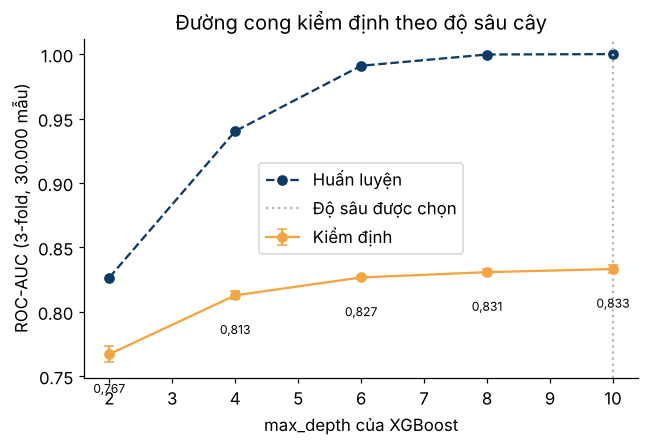

In [11]:
# Đường cong kiểm định: ảnh hưởng của độ sâu cây XGBoost (các siêu tham số khác giữ theo cấu hình tốt nhất)
bp = dict(SEARCH["XGB"]["best_params"]); bp.pop("max_depth", None); depths = [2, 4, 6, 8, 10]
rep, aug = BEST["XGB"]["rep"], BEST["XGB"]["aug"]
def _vc():
    X, y = Xtr[rep][sub], y_train[sub]; Xs = Xtr_sw["concat"][sub] if aug else None; out = []
    for d in depths:
        tr_sc, va_sc = [], []
        for tr, va in cv3.split(X, y):
            m, p = fit_predict(xgb(max_depth=d, **bp), X[tr], y[tr], X[va], aug, Xs[tr] if aug else None, Xs[va] if aug else None)
            va_sc.append(roc_auc_score(y[va], p)); tr_sc.append(roc_auc_score(y[tr], m.predict_proba(X[tr])[:, 1]))
        out.append((np.mean(tr_sc), np.mean(va_sc), np.std(va_sc)))
    return out
vc = cached(C(f"valcurve_{rep}{'_aug' if aug else ''}"), _vc)
SUM["val_curve"] = {"depth": depths, "train": [v[0] for v in vc], "val": [v[1] for v in vc], "val_sd": [v[2] for v in vc]}
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(depths, [v[0] for v in vc], "o--", color=NAVY, label="Huấn luyện")
ax.errorbar(depths, [v[1] for v in vc], yerr=[v[2] for v in vc], fmt="o-", color=OR, capsize=3, label="Kiểm định")
for d, v in zip(depths, vc): ax.text(d, v[1] - 0.03, vn(v[1]), ha="center", fontsize=8)
ax.axvline(SEARCH["XGB"]["best_params"]["max_depth"], color=GR, ls=":", label="Độ sâu được chọn")
ax.set_xlabel("max_depth của XGBoost"); ax.set_ylabel("ROC-AUC (3-fold, 30.000 mẫu)"); ax.legend(); ax.set_title("Đường cong kiểm định theo độ sâu cây")
savefig("fig15_duong_cong_kiem_dinh.png")

## 5. Mô hình đã tối ưu, thuật toán mới và mô hình tổ hợp (5-fold trên 80.000 mẫu)

In [12]:
NAME = {fam: f"{fam} · {BEST[fam]['label']} · tối ưu" for fam in ["XGB", "RF"]}
run_cv(NAME["XGB"], xgb(**SEARCH["XGB"]["best_params"]), BEST["XGB"]["rep"], BEST["XGB"]["aug"])
run_cv(NAME["RF"], rf(**SEARCH["RF"]["best_params"]), BEST["RF"]["rep"], BEST["RF"]["aug"])
NAME["ET"] = f"Extra Trees · {BEST['RF']['label']}"
run_cv(NAME["ET"], et(), BEST["RF"]["rep"], BEST["RF"]["aug"])
# Soft Voting: trung bình xác suất ngoài fold của RF và XGBoost đã tối ưu (trọng số bằng nhau, không cần huấn luyện thêm)
NAME["VOTE"] = "Voting RF + XGB · tối ưu"; pv = (OOF[NAME["XGB"]] + OOF[NAME["RF"]]) / 2; OOF[NAME["VOTE"]] = pv
rows_ = pd.DataFrame(ROWS)
for k, (tr, va) in enumerate(cv.split(Xtr["concat"], y_train)):
    ft = rows_[(rows_["Cấu hình"].isin([NAME["XGB"], NAME["RF"]])) & (rows_.Fold == k + 1)].fit_time.sum()
    ROWS.append({"Cấu hình": NAME["VOTE"], "Fold": k + 1, **scores(y_train[va], pv[va]), "train_roc_auc": np.nan, "fit_time": ft})
r = pd.DataFrame([x for x in ROWS if x["Cấu hình"] == NAME["VOTE"]]); print(f"{NAME['VOTE']:44s} ROC-AUC = {r.roc_auc.mean():.4f} ± {r.roc_auc.std(ddof=0):.4f}")

XGB · đối xứng + đếm + hóa lý · tối ưu       ROC-AUC = 0.8812 ± 0.0014  F1 = 0.8046  (0 s)
RF · ghép nối · tối ưu                       ROC-AUC = 0.8590 ± 0.0023  F1 = 0.7858  (0 s)
Extra Trees · ghép nối                       ROC-AUC = 0.8635 ± 0.0024  F1 = 0.7895  (0 s)
Voting RF + XGB · tối ưu                     ROC-AUC = 0.8855 ± 0.0016


## 6. So sánh trước – sau (cùng dữ liệu, cùng 5 fold, cùng chỉ số)

In [13]:
res = pd.DataFrame(ROWS); res.to_csv(f"{RES}/bkt3_cv_folds.csv", index=False); agg = res.groupby("Cấu hình", sort=False)
abl = pd.DataFrame({"ROC-AUC": agg.roc_auc.mean(), "ĐLC ROC-AUC": agg.roc_auc.std(ddof=0), "F1": agg.f1.mean(), "ĐLC F1": agg.f1.std(ddof=0),
                    "Recall": agg.recall.mean(), "Precision": agg.precision.mean(), "Accuracy": agg.accuracy.mean(),
                    "ROC-AUC train": agg.train_roc_auc.mean(), "Thời gian fit (s/fold)": agg.fit_time.mean()})
display(abl.round(4)); SUM["ablation"] = abl.round(6).reset_index().to_dict(orient="records")

,ROC-AUC,ĐLC ROC-AUC,F1,ĐLC F1,Recall,Precision,Accuracy,ROC-AUC train,Thời gian fit (s/fold)
Cấu hình,,,,,,,,,
LR · ghép nối (ban đầu),0.8067,0.0026,0.7386,0.0025,0.7562,0.7218,0.7324,0.8365,22.8628
RF · ghép nối (ban đầu),0.8582,0.0022,0.7834,0.0028,0.8091,0.7594,0.7764,1.0000,75.6276
XGB · ghép nối (ban đầu),0.8470,0.0017,0.7726,0.0015,0.7993,0.7475,0.7647,0.9277,45.4263
LR · ghép nối + dự đoán hai chiều,0.7838,0.0031,0.7154,0.0040,0.7348,0.6970,0.7077,0.8002,22.2990
RF · ghép nối + dự đoán hai chiều,0.8543,0.0025,0.7780,0.0015,0.8012,0.7561,0.7714,0.9994,74.7867
XGB · ghép nối + dự đoán hai chiều,0.8384,0.0032,0.7645,0.0037,0.7871,0.7433,0.7576,0.8879,46.6604
LR · đối xứng,0.7930,0.0027,0.7275,0.0030,0.7445,0.7114,0.7212,0.8094,8.3962
RF · đối xứng,0.8507,0.0029,0.7764,0.0029,0.8018,0.7526,0.7691,1.0000,47.7146
XGB · đối xứng,0.8534,0.0027,0.7758,0.0033,0.7955,0.7571,0.7701,0.9393,24.0657


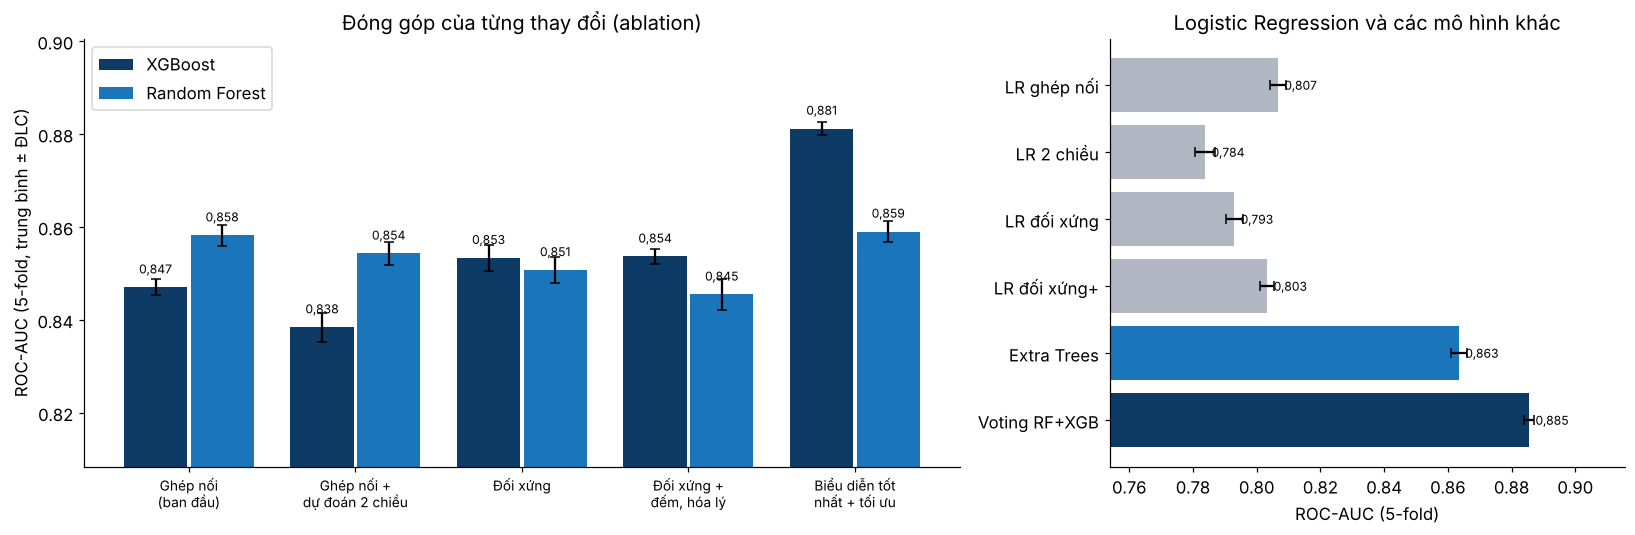

In [14]:
steps = ["ghép nối (ban đầu)", "ghép nối + dự đoán hai chiều", "đối xứng", "đối xứng + đếm + hóa lý"]
step_lab = ["Ghép nối\n(ban đầu)", "Ghép nối +\ndự đoán 2 chiều", "Đối xứng", "Đối xứng +\nđếm, hóa lý", "Biểu diễn tốt\nnhất + tối ưu"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.7, 1]})
for off, fam, c, n in [(-0.2, "XGB", NAVY, "XGBoost"), (0.2, "RF", BLUE, "Random Forest")]:
    rows_ = [f"{fam} · {s}" for s in steps] + [NAME[fam]]
    mu = abl.loc[rows_, "ROC-AUC"].values; sd = abl.loc[rows_, "ĐLC ROC-AUC"].values; x = np.arange(len(rows_)) + off
    ax[0].bar(x, mu, 0.38, yerr=sd, capsize=3, color=c, label=n)
    for xi, v in zip(x, mu): ax[0].text(xi, v + 0.003, vn(v), ha="center", fontsize=8)
ax[0].set_xticks(range(len(step_lab))); ax[0].set_xticklabels(step_lab, fontsize=9); ax[0].set_ylabel("ROC-AUC (5-fold, trung bình ± ĐLC)")
lo = abl["ROC-AUC"].drop([i for i in abl.index if i.startswith("LR")]).min(); ax[0].set_ylim(lo - 0.03, abl["ROC-AUC"].max() + 0.015)
ax[0].legend(loc="upper left"); ax[0].set_title("Đóng góp của từng thay đổi (ablation)")
others = [f"LR · {s}" for s in steps] + [NAME["ET"], NAME["VOTE"]]
lab_o = ["LR ghép nối", "LR 2 chiều", "LR đối xứng", "LR đối xứng+", "Extra Trees", "Voting RF+XGB"]
mu = abl.loc[others, "ROC-AUC"].values; sd = abl.loc[others, "ĐLC ROC-AUC"].values
ax[1].barh(lab_o[::-1], mu[::-1], xerr=sd[::-1], color=[NAVY, BLUE, GR, GR, GR, GR], capsize=3)
for i, v in enumerate(mu[::-1]): ax[1].text(v + 0.002, i, vn(v), va="center", fontsize=8)
ax[1].set_xlim(mu.min() - 0.03, abl["ROC-AUC"].max() + 0.03); ax[1].set_xlabel("ROC-AUC (5-fold)"); ax[1].set_title("Logistic Regression và các mô hình khác")
plt.tight_layout(); savefig("fig16_ablation.png")

## 7. Mô hình cuối: tập kiểm tra giữ lại và thuốc mới

In [15]:
cands = [NAME["XGB"], NAME["RF"], NAME["ET"], NAME["VOTE"]]
final_name = abl.loc[cands, "ROC-AUC"].idxmax(); print("Cấu hình có ROC-AUC kiểm định chéo cao nhất:", final_name); SUM["final_name"] = final_name
def fit_test(make, fam):
    rep, aug = BEST[fam]["rep"], BEST[fam]["aug"]
    m, p = fit_predict(make(), Xtr[rep], y_train, Xte[rep], aug, None, Xte_sw[rep] if aug else None)
    del m; gc.collect(); return p
p_x = cached(C(f"test_xgb_{BEST['XGB']['rep']}"), lambda: fit_test(lambda: xgb(**SEARCH["XGB"]["best_params"]), "XGB"))
p_r = cached(C(f"test_rf_{BEST['RF']['rep']}"), lambda: fit_test(lambda: rf(**SEARCH["RF"]["best_params"]), "RF"))
TEST = {"XGB · ghép nối (ban đầu)": scores(y_test, p_xgb0), "RF · ghép nối (ban đầu)": scores(y_test, p_rf0),
        NAME["XGB"]: scores(y_test, p_x), NAME["RF"]: scores(y_test, p_r), NAME["VOTE"]: scores(y_test, (p_x + p_r) / 2)}
tt = pd.DataFrame(TEST).T; tt["ROC-AUC kiểm định chéo"] = [abl.loc[i, "ROC-AUC"] for i in tt.index]
display(tt.round(4)); SUM["test"] = tt.round(6).to_dict(orient="index")
SUM["final_folds"] = res[res["Cấu hình"] == final_name][["Fold"] + METRICS].round(5).to_dict(orient="records")
pd.DataFrame({"drug1": test_df.drug1, "drug2": test_df.drug2, "label": y_test, "p_xgb_tuned": p_x, "p_rf_tuned": p_r}).to_csv(f"{RES}/bkt3_test_predictions.csv.gz", index=False)

Cấu hình có ROC-AUC kiểm định chéo cao nhất: Voting RF + XGB · tối ưu


,roc_auc,f1,recall,precision,accuracy,ROC-AUC kiểm định chéo
XGB · ghép nối (ban đầu),0.8525,0.7793,0.8103,0.7506,0.7706,0.8470
RF · ghép nối (ban đầu),0.8646,0.7892,0.8221,0.7589,0.7804,0.8582
XGB · đối xứng + đếm + hóa lý · tối ưu,0.8868,0.8104,0.8336,0.7885,0.8050,0.8812
RF · ghép nối · tối ưu,0.8647,0.7908,0.8230,0.7611,0.7823,0.8590
Voting RF + XGB · tối ưu,0.8908,0.8155,0.8411,0.7915,0.8098,0.8855


In [16]:
COLD[NAME["XGB"]] = cold_eval(f"xgb_best_{BEST['XGB']['rep']}{'_aug' if BEST['XGB']['aug'] else ''}", lambda: xgb(**SEARCH["XGB"]["best_params"]), BEST["XGB"]["rep"], BEST["XGB"]["aug"])
COLD[NAME["RF"]] = cold_eval(f"rf_best_{BEST['RF']['rep']}{'_aug' if BEST['RF']['aug'] else ''}", lambda: rf(**SEARCH["RF"]["best_params"]), BEST["RF"]["rep"], BEST["RF"]["aug"])
cold = pd.DataFrame(COLD).T; display(cold.round(4)); SUM["cold"] = cold.round(6).to_dict(orient="index")

,S1_one_new,S2_two_new
XGBoost ban đầu,0.7736,0.6801
Random Forest ban đầu,0.7990,0.7204
XGB · đối xứng + đếm + hóa lý · tối ưu,0.8027,0.7086
RF · ghép nối · tối ưu,0.7962,0.7160


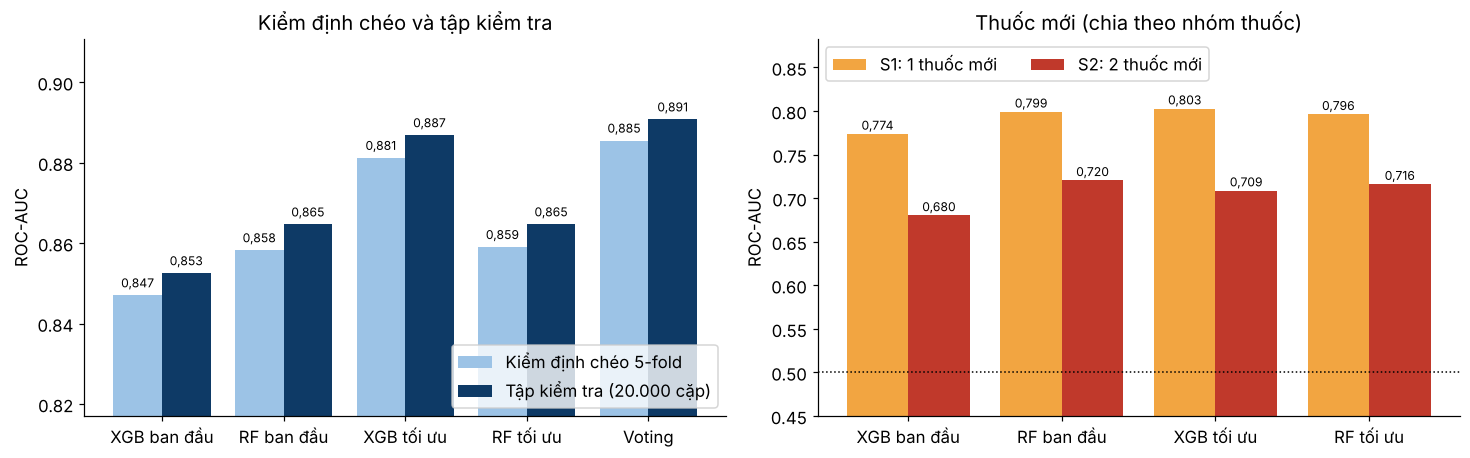

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.3))
nm = ["XGB · ghép nối (ban đầu)", "RF · ghép nối (ban đầu)", NAME["XGB"], NAME["RF"], NAME["VOTE"]]
short = ["XGB ban đầu", "RF ban đầu", "XGB tối ưu", "RF tối ưu", "Voting"]
x = np.arange(len(nm)); cvv = tt.loc[nm, "ROC-AUC kiểm định chéo"].values; tv = tt.loc[nm, "roc_auc"].values
ax[0].bar(x - 0.2, cvv, 0.4, color=LB, label="Kiểm định chéo 5-fold"); ax[0].bar(x + 0.2, tv, 0.4, color=NAVY, label="Tập kiểm tra (20.000 cặp)")
for xi, a, b in zip(x, cvv, tv):
    ax[0].text(xi - 0.2, a + 0.002, vn(a), ha="center", fontsize=8); ax[0].text(xi + 0.2, b + 0.002, vn(b), ha="center", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(short); ax[0].set_ylim(min(cvv.min(), tv.min()) - 0.03, max(cvv.max(), tv.max()) + 0.02)
ax[0].set_ylabel("ROC-AUC"); ax[0].legend(loc="lower right"); ax[0].set_title("Kiểm định chéo và tập kiểm tra")
cn = list(COLD.keys()); x = np.arange(len(cn))
ax[1].bar(x - 0.2, cold["S1_one_new"].values, 0.4, color=OR, label="S1: 1 thuốc mới"); ax[1].bar(x + 0.2, cold["S2_two_new"].values, 0.4, color=RED, label="S2: 2 thuốc mới")
for xi, a, b in zip(x, cold["S1_one_new"].values, cold["S2_two_new"].values):
    ax[1].text(xi - 0.2, a + 0.005, vn(a), ha="center", fontsize=8); ax[1].text(xi + 0.2, b + 0.005, vn(b), ha="center", fontsize=8)
ax[1].axhline(0.5, color="k", ls=":", lw=1); ax[1].set_xticks(x); ax[1].set_xticklabels(["XGB ban đầu", "RF ban đầu", "XGB tối ưu", "RF tối ưu"])
ax[1].set_ylim(0.45, cold.values.max() + 0.08); ax[1].set_ylabel("ROC-AUC"); ax[1].legend(loc="upper left", ncol=2); ax[1].set_title("Thuốc mới (chia theo nhóm thuốc)")
plt.tight_layout(); savefig("fig17_tong_quat_hoa.png")

## 8. Thí nghiệm kiểm tra thiên lệch theo bậc
Giữ nguyên 50.000 cặp dương, lấy lại 50.000 cặp âm sao cho **mỗi thuốc xuất hiện trong mẫu âm với tần suất tỷ lệ với số lần nó
xuất hiện trong mẫu dương**. So sánh (i) một mô hình “lối tắt” chỉ dùng bậc của hai thuốc và (ii) XGBoost trên cấu trúc hóa học
(cấu hình ban đầu, biểu diễn ghép nối), trên hai cách lấy mẫu âm, bằng kiểm định chéo 3-fold. Bậc chỉ dùng trong thí nghiệm chẩn
đoán này, không dùng trong mô hình cuối.

In [18]:
raw = pd.read_csv("../data/raw/ddi_pairs.csv.gz"); ids = set(drugs.drugbank_id)
known_pairs = set(map(tuple, np.sort(raw[raw.drug1.isin(ids) & raw.drug2.isin(ids)][["drug1", "drug2"]].values, axis=1)))
pos = pairs[pairs.label == 1][["drug1", "drug2"]]
if QUICK: pos = pos.iloc[:3000]
freq = pd.concat([pos.drug1, pos.drug2]).value_counts(); cand = freq.index.values; prob = (freq / freq.sum()).values
rng = np.random.default_rng(SEED); neg = set()
while len(neg) < len(pos):
    a, b = rng.choice(cand, 2, p=prob)
    if a != b:
        t = tuple(sorted((a, b)))
        if t not in known_pairs: neg.add(t)
negb = pd.DataFrame(sorted(neg), columns=["drug1", "drug2"])
balanced = pd.concat([pos.assign(label=1), negb.assign(label=0)], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
neg0 = pairs[pairs.label == 0][["drug1", "drug2"]].iloc[:len(pos)]
original = pd.concat([pos.assign(label=1), neg0.assign(label=0)], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
deg = drugs.set_index("drugbank_id")["degree"]
def deg_feats(d):
    a, b = np.log1p(deg.loc[d.drug1].values), np.log1p(deg.loc[d.drug2].values)
    return np.c_[np.minimum(a, b), np.maximum(a, b)]
DIAG = {}
for nm_, key, d in [("Mẫu âm ban đầu", "goc", original), ("Mẫu âm cân bằng theo bậc", "canbang", balanced)]:
    y = d.label.values
    a_deg = cross_val_score(LogisticRegression(), deg_feats(d), y, cv=cv3, scoring="roc_auc")
    a_xgb = cached(C(f"diag_{key}"), lambda: cross_val_score(xgb(), build_pairs(d, drugs, fps, "concat"), y, cv=cv3, scoring="roc_auc"))
    DIAG[nm_] = {"Chỉ dùng bậc": float(a_deg.mean()), "Chỉ dùng bậc ĐLC": float(a_deg.std()), "XGB cấu trúc": float(a_xgb.mean()), "XGB cấu trúc ĐLC": float(a_xgb.std())}
    print(nm_, {k: round(v, 4) for k, v in DIAG[nm_].items()})
SUM["degree_diag"] = DIAG

Mẫu âm ban đầu {'Chỉ dùng bậc': 0.8705, 'Chỉ dùng bậc ĐLC': 0.0023, 'XGB cấu trúc': 0.8482, 'XGB cấu trúc ĐLC': 0.0024}
Mẫu âm cân bằng theo bậc {'Chỉ dùng bậc': 0.6798, 'Chỉ dùng bậc ĐLC': 0.0022, 'XGB cấu trúc': 0.7154, 'XGB cấu trúc ĐLC': 0.0014}


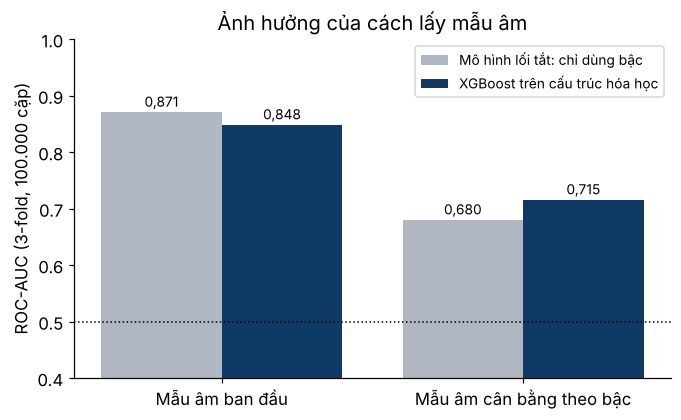

In [19]:
fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(2)
a = [DIAG[k]["Chỉ dùng bậc"] for k in DIAG]; b = [DIAG[k]["XGB cấu trúc"] for k in DIAG]
ax.bar(x - 0.2, a, 0.4, color=GR, label="Mô hình lối tắt: chỉ dùng bậc"); ax.bar(x + 0.2, b, 0.4, color=NAVY, label="XGBoost trên cấu trúc hóa học")
for xi, u, v in zip(x, a, b): ax.text(xi - 0.2, u + 0.01, vn(u), ha="center", fontsize=9); ax.text(xi + 0.2, v + 0.01, vn(v), ha="center", fontsize=9)
ax.axhline(0.5, color="k", ls=":", lw=1); ax.set_xticks(x); ax.set_xticklabels(list(DIAG.keys())); ax.set_ylim(0.4, 1.0)
ax.set_ylabel("ROC-AUC (3-fold, 100.000 cặp)"); ax.legend(loc="upper right", fontsize=9); ax.set_title("Ảnh hưởng của cách lấy mẫu âm")
savefig("fig18_lay_mau_am_theo_bac.png")

## 9. Lựa chọn mô hình cuối

In [20]:
cand_tab = abl.loc[[NAME["XGB"], NAME["RF"], NAME["ET"], NAME["VOTE"], "RF · ghép nối (ban đầu)", "XGB · ghép nối (ban đầu)"],
                   ["ROC-AUC", "ĐLC ROC-AUC", "F1", "Recall", "Thời gian fit (s/fold)"]]
display(cand_tab.round(4))
import sklearn, xgboost, platform
SUM["names"] = NAME
SUM["versions"] = {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__}
json.dump(SUM, open(f"{RES}/bkt3_summary.json", "w"), ensure_ascii=False, indent=1, default=str)
print("Đã lưu results/bkt3_summary.json, bkt3_cv_folds.csv, bkt3_test_predictions.csv.gz")

,ROC-AUC,ĐLC ROC-AUC,F1,Recall,Thời gian fit (s/fold)
Cấu hình,,,,,
XGB · đối xứng + đếm + hóa lý · tối ưu,0.8812,0.0014,0.8046,0.8240,59.1637
RF · ghép nối · tối ưu,0.8590,0.0023,0.7858,0.8154,477.3938
Extra Trees · ghép nối,0.8635,0.0024,0.7895,0.8172,137.1364
Voting RF + XGB · tối ưu,0.8855,0.0016,0.8100,0.8328,536.5575
RF · ghép nối (ban đầu),0.8582,0.0022,0.7834,0.8091,75.6276
XGB · ghép nối (ban đầu),0.8470,0.0017,0.7726,0.7993,45.4263


Đã lưu results/bkt3_summary.json, bkt3_cv_folds.csv, bkt3_test_predictions.csv.gz
